In [ ]:
#In this project, we are trying to predict S&P500 Binary Return by Macro Economics Variables, using XGBoost Model.
#Data Range:1977.2.1 ~ 2026.6.30(Since we do not have 30 Year T-bill data before 1977.2.1)
#Variables(X): S&P500's (Return, Variance, P/E Ratio, D/(P-1) Ratio, D/P Ratio, D/E Ratio), 
#              T-Bill(3M, 30Y, 30Y-3M), Inflation Rate, Unemployment Rate
#Please refer to the Separate Data Description file for more detail.

In [19]:
#library
import math
import yfinance as yf
import numpy as np
import pandas as pd
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
import datetime
from matplotlib import pyplot as plt
import seaborn as sns

In [3]:
#Stock Data
start_date = datetime.datetime(1976, 2, 1)
end_date = datetime.datetime(2026, 7, 1)
data = yf.Ticker("^GSPC")
hist = data.history(start=start_date, end=end_date)
df = pd.DataFrame(hist)

#Stock Data Cleaning
def date_formatting(input_date):
    input_date = str(input_date)
    year = input_date[:4]
    month = input_date[5:7]
    day = input_date[8:10]
    return year + month + day, year, month, day

#Creating a column to indicate the positive return by "1" & negative return by "0"
def binary_output(input):  
    if input >=0:
        return 1
    else:
        return 0


df=df.reset_index()
df['date'], df['year'], df['month'], df['day']= zip(*df.apply(lambda x: date_formatting(x['Date']),axis=1))
df= df[['date','year','month','day','Close','Volume']]
df = df.dropna()
df

,date,year,month,day,Close,Volume
0,19760202,1976,02,02,100.870003,24000000
1,19760203,1976,02,03,101.180000,34080000
2,19760204,1976,02,04,101.910004,38270000
3,19760205,1976,02,05,100.389999,33780000
4,19760206,1976,02,06,99.459999,27360000
...,...,...,...,...,...,...
12702,20260624,2026,06,24,7358.220215,5994860000
12703,20260625,2026,06,25,7357.490234,5565760000
12704,20260626,2026,06,26,7354.020020,9105600000
12705,20260629,2026,06,29,7440.430176,5794570000


In [4]:
#get variance of Close(252 days window)
df['variance'] = df['Close'].rolling(window=252).var()
df = df.dropna()
df


,date,year,month,day,Close,Volume,variance
251,19770128,1977,01,28,101.930000,22700000,4.012642
252,19770131,1977,01,31,102.029999,22920000,4.001854
253,19770201,1977,02,01,102.540001,23700000,3.993596
254,19770202,1977,02,02,102.360001,25700000,3.991836
255,19770203,1977,02,03,101.849998,23790000,3.974276
...,...,...,...,...,...,...,...
12702,20260624,2026,06,24,7358.220215,5994860000,123844.415722
12703,20260625,2026,06,25,7357.490234,5565760000,123087.185990
12704,20260626,2026,06,26,7354.020020,9105600000,122264.058140
12705,20260629,2026,06,29,7440.430176,5794570000,122064.102397


In [5]:
#Keeping only monthly data(end of month)
temp = df.pivot_table(index = ['year','month'], values=['date','Close','Volume','variance'], aggfunc = 'last')
temp = temp.reset_index()
del temp['date']
del temp['Volume']
temp


,year,month,Close,variance
0,1977,01,102.029999,4.001854
1,1977,02,99.820000,3.891659
2,1977,03,98.419998,4.056987
3,1977,04,98.440002,5.003800
4,1977,05,96.120003,5.940083
...,...,...,...,...
589,2026,02,6878.879883,261451.330863
590,2026,03,6528.520020,226795.327942
591,2026,04,7209.009766,137752.353630
592,2026,05,7580.060059,128633.049743


In [6]:
#reading macro data
macro_data = pd.read_csv('/Users/Ronnie/Desktop/Programming/Python/Python/Project/sp500_data.csv')

def date_formatting2(input_date):
    input_date = str(input_date)
    year = input_date[:4]
    month = input_date[5:7]
    return year + month, year, month

macro_data['date'], macro_data['year'], macro_data['month']= zip(*macro_data.apply(lambda x: date_formatting2(x['Date']),axis=1))
del macro_data['Date']
macro_data['Unemployment Rate'] /= 100
macro_data['TB3MS'] /= 100
macro_data['GS30'] /= 100
macro_data['Inflation Rate'] = macro_data['Consumer Price Index'] / macro_data['Consumer Price Index'].shift(12)
macro_data

,Dividend,Earnings,Consumer Price Index,Unemployment Rate,TB3MS,GS30,date,year,month,Inflation Rate
0,3.69,8.43,55.80,0.077,0.0488,NaN,197602,1976,02,NaN
1,3.69,8.66,55.90,0.076,0.0500,NaN,197603,1976,03,NaN
2,3.71,8.86,56.10,0.077,0.0486,NaN,197604,1976,04,NaN
3,3.74,9.05,56.50,0.074,0.0520,NaN,197605,1976,05,NaN
4,3.76,9.25,56.80,0.076,0.0541,NaN,197606,1976,06,NaN
...,...,...,...,...,...,...,...,...,...,...
600,80.08,254.69,326.79,0.044,0.0360,0.0476,202602,2026,02,1.024163
601,80.37,261.72,330.21,0.043,0.0361,0.0485,202603,2026,03,1.032552
602,80.81,272.94,333.02,0.043,0.0361,0.0491,202604,2026,04,1.038092
603,81.26,284.17,335.12,0.043,0.0360,0.0503,202605,2026,05,1.042461


In [7]:
#merging 2 tables
result = pd.merge(temp, macro_data, on=['year','month'], how='inner')

def log_diff(val1, val2):
    result = math.log(val1) - math.log(val2)
    return result

def take_log(val):
    result = math.log(val)
    return result

result['pe_ratio'] = result.apply(lambda x: log_diff(x['Close'], x['Earnings']),axis=1)
result['div_yield'] = result['Dividend']/result['Close'].shift(1)
result['div_yield'] = result.apply(lambda x: take_log(x['div_yield']),axis=1)
result['dp_ratio'] = result.apply(lambda x: log_diff(x['Dividend'], x['Close']),axis=1)
result['de_ratio'] = result.apply(lambda x: log_diff(x['Dividend'], x['Earnings']),axis=1)
result['tbill_ls_spread'] = result['GS30'] - result['TB3MS']
result['return'] = (result['Close']/result['Close'].shift(1))-1
result['binary_return'] = result.apply(lambda x: binary_output(x['return']),axis=1)
result = result.dropna()
result

,year,month,Close,variance,Dividend,Earnings,Consumer Price Index,Unemployment Rate,TB3MS,GS30,date,Inflation Rate,pe_ratio,div_yield,dp_ratio,de_ratio,tbill_ls_spread,return,binary_return
1,1977,02,99.820000,3.891659,4.14,10.02,59.10,0.076,0.0467,0.0775,197702,1.059140,2.298785,-3.204571,-3.182673,-0.883887,0.0308,-0.021660,0
2,1977,03,98.419998,4.056987,4.19,10.08,59.50,0.074,0.0460,0.0780,197703,1.064401,2.278691,-3.170668,-3.156543,-0.877853,0.0320,-0.014025,0
3,1977,04,98.440002,5.003800,4.25,10.19,60.00,0.072,0.0454,0.0773,197704,1.069519,2.268040,-3.142325,-3.142528,-0.874488,0.0319,0.000203,1
4,1977,05,96.120003,5.940083,4.30,10.31,60.30,0.070,0.0496,0.0780,197705,1.067257,2.232483,-3.130832,-3.106982,-0.874499,0.0284,-0.023568,0
5,1977,06,100.480003,6.424566,4.36,10.42,60.70,0.072,0.0502,0.0764,197706,1.068662,2.266232,-3.093125,-3.137487,-0.871255,0.0262,0.045360,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
589,2026,02,6878.879883,261451.330863,80.08,254.69,326.79,0.044,0.0360,0.0476,202602,1.024163,3.296164,-4.461891,-4.453185,-1.157021,0.0116,-0.008668,0
590,2026,03,6528.520020,226795.327942,80.37,261.72,330.21,0.043,0.0361,0.0485,202603,1.032552,3.216660,-4.449570,-4.397295,-1.180634,0.0124,-0.050933,0
591,2026,04,7209.009766,137752.353630,80.81,272.94,333.02,0.043,0.0361,0.0491,202604,1.038092,3.273835,-4.391835,-4.490986,-1.217151,0.0130,0.104233,1
592,2026,05,7580.060059,128633.049743,81.26,284.17,335.12,0.043,0.0360,0.0503,202605,1.042461,3.283704,-4.485433,-4.535623,-1.251919,0.0143,0.051470,1


In [8]:
df = result.copy()
df = df.drop(columns = ['year', 'month', 'Close', 'Consumer Price Index', 'date'])
df

,variance,Dividend,Earnings,Unemployment Rate,TB3MS,GS30,Inflation Rate,pe_ratio,div_yield,dp_ratio,de_ratio,tbill_ls_spread,return,binary_return
1,3.891659,4.14,10.02,0.076,0.0467,0.0775,1.059140,2.298785,-3.204571,-3.182673,-0.883887,0.0308,-0.021660,0
2,4.056987,4.19,10.08,0.074,0.0460,0.0780,1.064401,2.278691,-3.170668,-3.156543,-0.877853,0.0320,-0.014025,0
3,5.003800,4.25,10.19,0.072,0.0454,0.0773,1.069519,2.268040,-3.142325,-3.142528,-0.874488,0.0319,0.000203,1
4,5.940083,4.30,10.31,0.070,0.0496,0.0780,1.067257,2.232483,-3.130832,-3.106982,-0.874499,0.0284,-0.023568,0
5,6.424566,4.36,10.42,0.072,0.0502,0.0764,1.068662,2.266232,-3.093125,-3.137487,-0.871255,0.0262,0.045360,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
589,261451.330863,80.08,254.69,0.044,0.0360,0.0476,1.024163,3.296164,-4.461891,-4.453185,-1.157021,0.0116,-0.008668,0
590,226795.327942,80.37,261.72,0.043,0.0361,0.0485,1.032552,3.216660,-4.449570,-4.397295,-1.180634,0.0124,-0.050933,0
591,137752.353630,80.81,272.94,0.043,0.0361,0.0491,1.038092,3.273835,-4.391835,-4.490986,-1.217151,0.0130,0.104233,1
592,128633.049743,81.26,284.17,0.043,0.0360,0.0503,1.042461,3.283704,-4.485433,-4.535623,-1.251919,0.0143,0.051470,1


In [9]:
#Scaling the Train & Test Data
x = df.drop(columns = ['binary_return'])
y = df[['binary_return']]
training_data_len = math.ceil(len(df)*0.7)
scaler = StandardScaler()

x_train = x.iloc[0:training_data_len,:]
x_test = x.iloc[training_data_len:-1,:] #Prevent fitted data from polluting the test data set
var_list = x_train.columns
x_train = x_train.astype(np.float64)
x_test = x_test.astype(np.float64)
x_train_s = scaler.fit_transform(x_train)
x_test_s = scaler.transform(x_test)

y_train = y.iloc[1:training_data_len+1,:]
y_train = y_train.values.ravel()

var_list = x_train.columns



In [10]:
#Building XGBoost Model
xgb = XGBClassifier(objective = 'binary:logistic', random_state = 42)
xgb.fit(x_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [11]:
#Applying XGBoost Model to Test Data
predictions = xgb.predict(x_test)
predictions_with_prob = xgb.predict_proba(x_test)

In [12]:
#Result
valid = result[training_data_len+1:]
valid['Predictions'] = predictions
valid['class_1_prob'] = predictions_with_prob[:,[1]]
valid

,year,month,Close,variance,Dividend,Earnings,Consumer Price Index,Unemployment Rate,TB3MS,GS30,...,Inflation Rate,pe_ratio,div_yield,dp_ratio,de_ratio,tbill_ls_spread,return,binary_return,Predictions,class_1_prob
418,2011,11,1246.959961,3900.865627,26.01,86.96,226.23,0.086,0.0001,0.0302,...,1.033958,2.663016,-3.875054,-3.869983,-1.206967,0.0301,-0.005059,0,1,0.918303
419,2011,12,1257.599976,3912.672077,26.43,86.95,225.67,0.085,0.0001,0.0298,...,1.029610,2.671627,-3.853964,-3.862461,-1.190834,0.0297,0.008533,1,1,0.847508
420,2012,01,1312.410034,3992.943782,26.74,87.48,226.67,0.083,0.0003,0.0303,...,1.029289,2.708210,-3.850800,-3.893460,-1.185250,0.0300,0.043583,1,1,0.659671
421,2012,02,1365.680054,4332.693972,27.04,88.01,227.66,0.083,0.0009,0.0311,...,1.028693,2.741957,-3.882303,-3.922091,-1.180133,0.0302,0.040589,1,1,0.978521
422,2012,03,1408.469971,5403.096212,27.35,88.54,229.39,0.082,0.0008,0.0328,...,1.026491,2.766805,-3.910691,-3.941543,-1.174738,0.0320,0.031332,1,1,0.512478
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
589,2026,02,6878.879883,261451.330863,80.08,254.69,326.79,0.044,0.0360,0.0476,...,1.024163,3.296164,-4.461891,-4.453185,-1.157021,0.0116,-0.008668,0,0,0.086403
590,2026,03,6528.520020,226795.327942,80.37,261.72,330.21,0.043,0.0361,0.0485,...,1.032552,3.216660,-4.449570,-4.397295,-1.180634,0.0124,-0.050933,0,0,0.173440
591,2026,04,7209.009766,137752.353630,80.81,272.94,333.02,0.043,0.0361,0.0491,...,1.038092,3.273835,-4.391835,-4.490986,-1.217151,0.0130,0.104233,1,0,0.036393
592,2026,05,7580.060059,128633.049743,81.26,284.17,335.12,0.043,0.0360,0.0503,...,1.042461,3.283704,-4.485433,-4.535623,-1.251919,0.0143,0.051470,1,0,0.015844


In [13]:
#Get the success rate of the prediction
Total = len(valid)
success_case = len(valid[valid['binary_return']==valid['Predictions']])
success_rate = success_case/Total
success_rate

0.4318181818181818

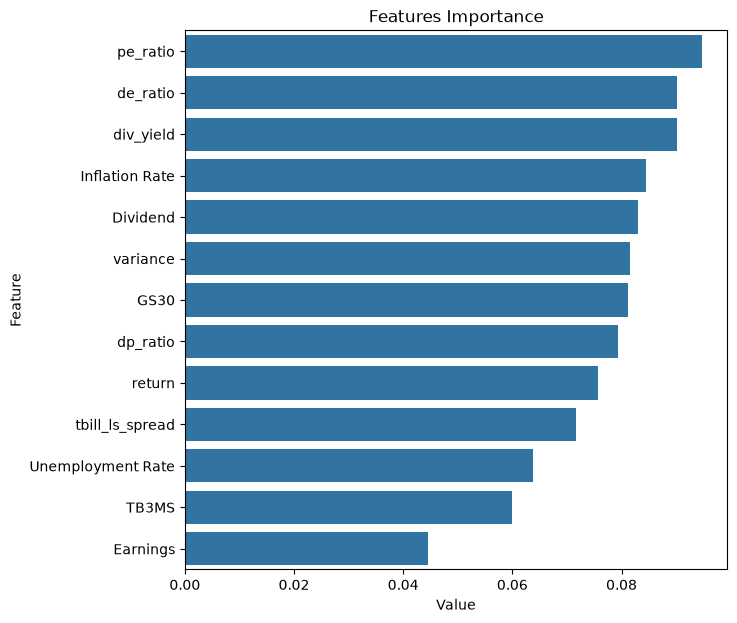

In [14]:
#Feature Importance
feature_imp = pd.DataFrame(sorted(zip(xgb.feature_importances_,var_list)), columns=['Value','Feature'])

plt.figure(figsize=(7, 7))
sns.barplot(x="Value", y="Feature", data=feature_imp.nlargest(20,"Value").sort_values(by="Value", ascending=False))
plt.title('Features Importance')
plt.show()

In [15]:
def correctness(val1, val2):
    if val1 == val2:
        return 1
    else:
        return 0


valid['Correct'] = valid.apply(lambda x: correctness(x['binary_return'], x['Predictions']),axis=1)

<Axes: xlabel='date'>

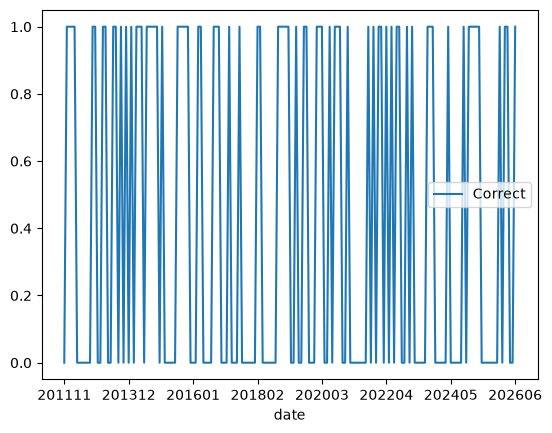

In [16]:
accuracy = valid[['date','Correct']]
accuracy = accuracy.pivot_table(index='date', values="Correct")
accuracy.plot()

In [17]:
#Hard to observe the periods with wrong predictions

In [18]:
accuracy = valid[['year','month','Correct']]
accuracy = accuracy.pivot_table(index='year', values="Correct")
accuracy

,Correct
year,
2011,0.500000
2012,0.416667
2013,0.500000
2014,0.750000
2015,0.500000
2016,0.416667
2017,0.166667
2018,0.416667
2019,0.416667


In [ ]:
#During 2022 to 2026(June), the model only perform well in 2014, 2020 and 2022. More Variables are needed to
#improve the performance. For futher research, we could try adding more variables and appliying PCA to reduce
#the dimension of the variables(especially useful for dealing with the variables with high corrlation)